# I. SETUP

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from scipy.stats import ttest_ind, t


# === Parameters ===
FPS = 30  # Hz
START =  5  # Seconds (to trim from the start)
ADAPT_TIME = 60*5 # Seconds (to trim from the start of the experiment)
END = 15  # Seconds (to trim from the end)
TIME_STEP = 60  # Seconds (to define time intervals)
N_BOOTS = 1000
ALPHA = 0.05
RNG = np.random.default_rng(0)


# === Directories ===
ROOT_DIR = '.'
INPUT_DIR = os.path.join(ROOT_DIR, 'processed_videos')
OUTPUT_DIR = os.path.join(ROOT_DIR, 'processed_counts')
os.makedirs(OUTPUT_DIR, exist_ok=True)


# === Helper functions ===
def find_clusters(t_vals, threshold):
    clusters = []
    current = []

    for i, val in enumerate(t_vals):
        if abs(val) > threshold:
            current.append(i)
        else:
            if current:
                clusters.append(current)
                current = []

    if current:
        clusters.append(current)

    return clusters

def cluster_statistic(t_vals, clusters):
    return [np.sum(np.abs(t_vals[c])) for c in clusters]

# II. DATA INSPECTION

In [2]:
# Load data
count_path = os.path.join(INPUT_DIR, 'prey_counts.csv')
raw_count_df = pd.read_csv(count_path)

raw_count_df.shape

(27600, 61)

In [3]:
# Create a copy to work on it
count_df = raw_count_df.copy()

# Initial trimming (5 s), to compensate for:
#  - the time required to close the experimental-room door, and
#  - the frame buffer (5 frames) introduced by the binarization process.
count_df = count_df.iloc[START * FPS:].reset_index(drop=True)
count_df.shape

(27450, 61)

In [4]:
count_df.head()

,2025_09_26_08_WT_2lux_8dpf_peu.avi,2025_11_26_06_WT_2lux_8dpf_bcp.avi,2025_11_26_04_WT_2lux_8dpf_bcp.avi,2025_11_26_02_WT_2lux_8dpf_peu.avi,2025_11_26_10_WT_2lux_8dpf_bcp.avi,2025_11_26_00_WT_2lux_8dpf_peu.avi,2025_11_26_11_MeCP2_2lux_8dpf_peu.avi,2025_11_26_03_MeCP2_2lux_8dpf_peu.avi,2025_09_26_00_MeCP2_2lux_8dpf_peu.avi,2025_09_26_04_WT_2lux_8dpf_peu.avi,...,2026_04_10_10_MeCP2_30lux_8dpf_peu.avi,2026_04_10_06_MeCP2_30lux_8dpf_peu.avi,2026_04_10_03_WT_30lux_8dpf_peu.avi,2026_04_10_02_MeCP2_30lux_8dpf_peu.avi,2026_04_10_07_WT_30lux_8dpf_peu.avi,2026_04_10_08_MeCP2_30lux_8dpf_peu.avi,2026_04_10_13_WT_30lux_8dpf_peu.avi,2026_04_10_12_MeCP2_30lux_8dpf_peu.avi,2026_04_10_14_MeCP2_30lux_8dpf_peu.avi,2026_04_10_11_WT_30lux_8dpf_peu.avi
0,38,35,29,31,38,25,32,35,17,29,...,18,25,36,36,32,32,35,41,27,30
1,37,34,30,31,37,25,32,35,18,27,...,19,25,33,34,36,34,36,41,27,30
2,37,38,29,31,37,24,32,35,18,30,...,19,25,32,33,36,32,36,42,26,30
3,35,39,29,30,38,24,33,35,19,30,...,19,25,32,35,36,33,34,45,26,31
4,34,38,30,32,36,24,32,34,20,30,...,20,25,31,33,35,33,34,44,26,32


In [5]:
count_df.tail()

,2025_09_26_08_WT_2lux_8dpf_peu.avi,2025_11_26_06_WT_2lux_8dpf_bcp.avi,2025_11_26_04_WT_2lux_8dpf_bcp.avi,2025_11_26_02_WT_2lux_8dpf_peu.avi,2025_11_26_10_WT_2lux_8dpf_bcp.avi,2025_11_26_00_WT_2lux_8dpf_peu.avi,2025_11_26_11_MeCP2_2lux_8dpf_peu.avi,2025_11_26_03_MeCP2_2lux_8dpf_peu.avi,2025_09_26_00_MeCP2_2lux_8dpf_peu.avi,2025_09_26_04_WT_2lux_8dpf_peu.avi,...,2026_04_10_10_MeCP2_30lux_8dpf_peu.avi,2026_04_10_06_MeCP2_30lux_8dpf_peu.avi,2026_04_10_03_WT_30lux_8dpf_peu.avi,2026_04_10_02_MeCP2_30lux_8dpf_peu.avi,2026_04_10_07_WT_30lux_8dpf_peu.avi,2026_04_10_08_MeCP2_30lux_8dpf_peu.avi,2026_04_10_13_WT_30lux_8dpf_peu.avi,2026_04_10_12_MeCP2_30lux_8dpf_peu.avi,2026_04_10_14_MeCP2_30lux_8dpf_peu.avi,2026_04_10_11_WT_30lux_8dpf_peu.avi
27445,28,39,31,26,35,19,30,29,18,24,...,17,15,29,24,32,29,30,33,21,23
27446,29,39,31,28,35,19,30,29,18,23,...,17,15,29,22,32,29,30,33,21,24
27447,29,40,31,28,34,18,30,29,18,23,...,17,15,29,25,32,29,30,34,21,25
27448,28,40,32,27,35,18,30,29,18,24,...,17,15,28,24,32,29,31,34,21,25
27449,30,40,32,26,35,17,30,30,18,24,...,19,15,28,23,33,29,30,35,22,25


In [6]:
count_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27450 entries, 0 to 27449
Data columns (total 61 columns):
 #   Column                                      Non-Null Count  Dtype
---  ------                                      --------------  -----
 0   2025_09_26_08_WT_2lux_8dpf_peu.avi          27450 non-null  int64
 1   2025_11_26_06_WT_2lux_8dpf_bcp.avi          27450 non-null  int64
 2   2025_11_26_04_WT_2lux_8dpf_bcp.avi          27450 non-null  int64
 3   2025_11_26_02_WT_2lux_8dpf_peu.avi          27450 non-null  int64
 4   2025_11_26_10_WT_2lux_8dpf_bcp.avi          27450 non-null  int64
 5   2025_11_26_00_WT_2lux_8dpf_peu.avi          27450 non-null  int64
 6   2025_11_26_11_MeCP2_2lux_8dpf_peu.avi       27450 non-null  int64
 7   2025_11_26_03_MeCP2_2lux_8dpf_peu.avi       27450 non-null  int64
 8   2025_09_26_00_MeCP2_2lux_8dpf_peu.avi       27450 non-null  int64
 9   2025_09_26_04_WT_2lux_8dpf_peu.avi          27450 non-null  int64
 10  2025_11_26_05_MeCP2_2lux_8dpf_bcp.

# III. MONOTONIC REGRESSION & NORMALIZATION

In [7]:
# Initialize non-increasing isotonic regression model
iso_reg = IsotonicRegression(increasing=False, out_of_bounds='clip')

# Get time points and ticks
T, n_files = count_df.shape
time_points = np.arange(T)

# List of files (experiments)
files = list(count_df.columns)


# ==================================================================
#   DENOIZING: Fitting an isotonic regression for each experiment
# ==================================================================

denoised_dict = {}

for f in files:
    y = count_df[f].to_numpy(dtype=float)
    denoised_dict[f] = iso_reg.fit_transform(time_points, y)

denoised_df = pd.DataFrame(denoised_dict, index=count_df.index)

print("denoised_df shape before adaptation time:", denoised_df.shape)
print()
print(
    "Average prey count before adaptation time: "
    f"{denoised_df.iloc[0, :].mean().round(1)} "
    f"± {denoised_df.iloc[0, :].std().round(1)}"
)
print()
print("-"*20)
print()

# Second trimming (60*5 s), in order:
#  - to start comparison after adaptation time
# Final trimming (15 s), in order to:
#  - avoid the artificial drop in prey count produced by the regression, 
#    at the end of the time series, and
#  - obtain a final analysis duration of 10 min.
denoised_df = denoised_df.iloc[ADAPT_TIME*FPS: -END*FPS].reset_index(drop=True)

print("denoised_df shape after adaptation time:", denoised_df.shape)
print()
print(
    "Prey count after adaptation time: "
    f"{denoised_df.iloc[0, :].mean().round(1)} "
    f"± {denoised_df.iloc[0, :].std().round(1)}"
)
print()
print("-"*20)
print()

denoised_df.to_csv(
    os.path.join(OUTPUT_DIR, 'denoised_prey_counts.csv'), 
    index=False
)

# Update array of time points
T, n_files = denoised_df.shape
time_points = np.arange(T)
tick_positions = np.arange(0, T+1, TIME_STEP * FPS)  # Frames
tick_labels = (tick_positions.astype(dtype='float') / FPS) / 60  # Minutes
tick_labels = tick_labels.astype(dtype='int')


# =====================================================
#    NORMALIZING: Dividing by initial value (at t=0)
# =====================================================

normalized_dict = {}

for f in files:
    normalized_dict[f] = denoised_df[f] / denoised_df[f][0]

normalized_df = pd.DataFrame(normalized_dict, index=denoised_df.index)

print("normalized_df shape:", normalized_df.shape)

normalized_df.to_csv(
    os.path.join(OUTPUT_DIR, 'normalized_prey_counts.csv'), 
    index=False
)

denoised_df shape before adaptation time: (27450, 61)

Average prey count before adaptation time: 34.6 ± 6.0

--------------------

denoised_df shape after adaptation time: (18000, 61)

Prey count after adaptation time: 31.3 ± 6.5

--------------------

normalized_df shape: (18000, 61)


# IV. ANALYSIS

## IV. 1. Define main datasets

In [8]:
wt_2lux_data = normalized_df[[f for f in files if "WT_2lux" in f]].to_numpy()
T, n_wt_2lux = wt_2lux_data.shape

wt_30lux_data = normalized_df[[f for f in files if "WT_30lux" in f]].to_numpy()
T, n_wt_30lux = wt_30lux_data.shape

mecp2_2lux_data = normalized_df[[f for f in files if "MeCP2_2lux" in f]].to_numpy()
T, n_mecp2_2lux = mecp2_2lux_data.shape

mecp2_30lux_data = normalized_df[[f for f in files if "MeCP2_30lux" in f]].to_numpy()
T, n_mecp2_30lux = mecp2_30lux_data.shape


print("n_wt_2lux:", n_wt_2lux)
print("n_wt_30lux:", n_wt_30lux)
print("n_mecp2_2lux:", n_mecp2_2lux)
print("n_mecp2_30lux:", n_mecp2_30lux)

n_wt_2lux: 15
n_wt_30lux: 15
n_mecp2_2lux: 15
n_mecp2_30lux: 16


## IV.2. Descriptive statistics

In [9]:
wt_2lux_rem = wt_2lux_data[-1, :]
wt_30lux_rem = wt_30lux_data[-1, :]
mecp2_2lux_rem = mecp2_2lux_data[-1, :]
mecp2_30lux_rem = mecp2_30lux_data[-1, :]

rem_df = pd.DataFrame(
    data=[
        [np.mean(wt_2lux_rem), np.std(wt_2lux_rem)],
        [np.mean(wt_30lux_rem), np.std(wt_30lux_rem)],
        [np.mean(mecp2_2lux_rem), np.std(mecp2_2lux_rem)],
        [np.mean(mecp2_30lux_rem), np.std(mecp2_30lux_rem)]
    ],
    index=['wt_2lux', 'wt_30lux', 'mecp2_2lux', 'mecp2_30lux'],
    columns=['mean', 'std']
)
print("Number of rotifers (norm) remaining at the end (t=10min)")
display(rem_df.round(4))

Number of rotifers (norm) remaining at the end (t=10min)


,mean,std
wt_2lux,0.8333,0.0810
wt_30lux,0.8382,0.1150
mecp2_2lux,0.9172,0.0478
mecp2_30lux,0.7706,0.1096


In [10]:
wt_2lux_eat = 1 - wt_2lux_rem
wt_30lux_eat = 1 - wt_30lux_rem
mecp2_2lux_eat = 1 - mecp2_2lux_rem
mecp2_30lux_eat = 1 - mecp2_30lux_rem

eat_df = pd.DataFrame(
    data=[
        [np.mean(wt_2lux_eat), np.std(wt_2lux_eat)],
        [np.mean(wt_30lux_eat), np.std(wt_30lux_eat)],
        [np.mean(mecp2_2lux_eat), np.std(mecp2_2lux_eat)],
        [np.mean(mecp2_30lux_eat), np.std(mecp2_30lux_eat)]
    ],
    index=['wt_2lux', 'wt_30lux', 'mecp2_2lux', 'mecp2_30lux'],
    columns=['mean', 'std']
)
print("Number of rotifers (norm) eaten to the end (t=10min)")
display(eat_df.round(4))

Number of rotifers (norm) eaten to the end (t=10min)


,mean,std
wt_2lux,0.1667,0.0810
wt_30lux,0.1618,0.1150
mecp2_2lux,0.0828,0.0478
mecp2_30lux,0.2294,0.1096


## IV. 3. Two-sided cluster-based permutation tests (and bootstrapping)

In [11]:
# === 2lux: wt vs mecp2 ===
t_obs_2lux, _ = ttest_ind(
    wt_2lux_data.T,
    mecp2_2lux_data.T,
    equal_var=False,  # Welch's t
    axis=0
)
t_threshold_2lux = t.ppf(
    1 - ALPHA/2,  # Two-sided
    n_wt_2lux + n_mecp2_2lux - 2  # Degrees of freedom
)
clusters_obs_2lux = find_clusters(t_obs_2lux, t_threshold_2lux)
cluster_stats_obs_2lux = cluster_statistic(t_obs_2lux, clusters_obs_2lux)


# === 30lux: wt vs mecp2 ===
t_obs_30lux, _ = ttest_ind(
    wt_30lux_data.T,
    mecp2_30lux_data.T,
    equal_var=False,  # Welch's t
    axis=0
)
t_threshold_30lux = t.ppf(
    1 - ALPHA/2,  # Two-sided
    n_wt_30lux + n_mecp2_30lux - 2  # Degrees of freedom
)
clusters_obs_30lux = find_clusters(t_obs_30lux, t_threshold_30lux)
cluster_stats_obs_30lux = cluster_statistic(t_obs_30lux, clusters_obs_30lux)



# === wt: 2lux vs 30lux ===
t_obs_wt, _ = ttest_ind(
    wt_2lux_data.T,
    wt_30lux_data.T,
    equal_var=False,  # Welch's t
    axis=0
)
t_threshold_wt = t.ppf(
    1 - ALPHA/2,  # Two-sided
    n_wt_2lux + n_wt_30lux - 2  # Degrees of freedom
)
clusters_obs_wt = find_clusters(t_obs_wt, t_threshold_wt)
cluster_stats_obs_wt = cluster_statistic(t_obs_wt, clusters_obs_wt)


# === mecp2: 2lux vs 30lux ===
t_obs_mecp2, _ = ttest_ind(
    mecp2_2lux_data.T,
    mecp2_30lux_data.T,
    equal_var=False,  # Welch's t
    axis=0
)
t_threshold_mecp2 = t.ppf(
    1 - ALPHA/2,  # Two-sided
    n_mecp2_2lux + n_mecp2_30lux - 2  # Degrees of freedom
)
clusters_obs_mecp2 = find_clusters(t_obs_mecp2, t_threshold_mecp2)
cluster_stats_obs_mecp2 = cluster_statistic(t_obs_mecp2, clusters_obs_mecp2)

/tmp/ipykernel_78593/3635803705.py:2: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  t_obs_2lux, _ = ttest_ind(
/tmp/ipykernel_78593/3635803705.py:17: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  t_obs_30lux, _ = ttest_ind(
/tmp/ipykernel_78593/3635803705.py:33: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  t_obs_wt, _ = ttest_ind(
/tmp/ipykernel_78593/3635803705.py:48: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  t_obs_mecp2, _ = ttest_ind(


In [12]:
# === Prepare datasets for permutations ===
all_2lux_data = np.concatenate([wt_2lux_data, mecp2_2lux_data], axis=1)
all_30lux_data = np.concatenate([wt_30lux_data, mecp2_30lux_data], axis=1)
all_wt_data = np.concatenate([wt_2lux_data, wt_30lux_data], axis=1)
all_mecp2_data = np.concatenate([mecp2_2lux_data, mecp2_30lux_data], axis=1)


# === Pre-allocated arrays to store data from boots and perms ===
wt_2lux_boots = np.zeros((N_BOOTS, T))
wt_30lux_boots = np.zeros((N_BOOTS, T))
mecp2_2lux_boots = np.zeros((N_BOOTS, T))
mecp2_30lux_boots = np.zeros((N_BOOTS, T))

max_cluster_stats_2lux = np.zeros(N_BOOTS)
max_cluster_stats_30lux = np.zeros(N_BOOTS)
max_cluster_stats_wt = np.zeros(N_BOOTS)
max_cluster_stats_mecp2 = np.zeros(N_BOOTS)


for b in range(N_BOOTS):

    # ====================================
    #    CI of the mean (bootstrapping)
    # ====================================
    
    wt_2lux_idx = RNG.integers(0, n_wt_2lux, size=n_wt_2lux)
    wt_2lux_b = wt_2lux_data[:, wt_2lux_idx]
    wt_2lux_boots[b] = np.mean(wt_2lux_b, axis=1)

    wt_30lux_idx = RNG.integers(0, n_wt_30lux, size=n_wt_30lux)
    wt_30lux_b = wt_30lux_data[:, wt_30lux_idx]
    wt_30lux_boots[b] = np.mean(wt_30lux_b, axis=1)

    mecp2_2lux_idx = RNG.integers(0, n_mecp2_2lux, size=n_mecp2_2lux)
    mecp2_2lux_b = mecp2_2lux_data[:, mecp2_2lux_idx]
    mecp2_2lux_boots[b] = np.mean(mecp2_2lux_b, axis=1)

    mecp2_30lux_idx = RNG.integers(0, n_mecp2_30lux, size=n_mecp2_30lux)
    mecp2_30lux_b = mecp2_30lux_data[:, mecp2_30lux_idx]
    mecp2_30lux_boots[b] = np.mean(mecp2_30lux_b, axis=1)


    # ======================================
    #    Cluster statistics (permutation)
    # ======================================
    
    # --- 2lux: wt vs mecp2 ---
    perm_idx_2lux = RNG.permutation(n_wt_2lux + n_mecp2_2lux)
    wt_2lux_data_p = all_2lux_data[:, perm_idx_2lux[:n_wt_2lux]]
    mecp2_2lux_data_p = all_2lux_data[:, perm_idx_2lux[n_wt_2lux:]]

    t_perm_2lux, _ = ttest_ind(
        wt_2lux_data_p.T,
        mecp2_2lux_data_p.T,
        equal_var=False,
        axis=0
    )
    clusters_perm_2lux = find_clusters(t_perm_2lux, t_threshold_2lux)

    if clusters_perm_2lux:
        max_cluster_stats_2lux[b] = np.max(
            cluster_statistic(t_perm_2lux, clusters_perm_2lux)
        )
    else:
        max_cluster_stats_2lux[b] = 0


    # --- 30lux: wt vs mecp2 ---
    perm_idx_30lux = RNG.permutation(n_wt_30lux + n_mecp2_30lux)
    wt_30lux_data_p = all_30lux_data[:, perm_idx_30lux[:n_wt_30lux]]
    mecp2_30lux_data_p = all_30lux_data[:, perm_idx_30lux[n_wt_30lux:]]

    t_perm_30lux, _ = ttest_ind(
        wt_30lux_data_p.T,
        mecp2_30lux_data_p.T,
        equal_var=False,
        axis=0
    )
    clusters_perm_30lux = find_clusters(t_perm_30lux, t_threshold_30lux)

    if clusters_perm_30lux:
        max_cluster_stats_30lux[b] = np.max(
            cluster_statistic(t_perm_30lux, clusters_perm_30lux)
        )
    else:
        max_cluster_stats_30lux[b] = 0


    # --- wt: 2lux vs 30lux ---
    perm_idx_wt = RNG.permutation(n_wt_2lux + n_wt_30lux)
    wt_2lux_data_p = all_wt_data[:, perm_idx_wt[:n_wt_2lux]]
    wt_30lux_data_p = all_wt_data[:, perm_idx_wt[n_wt_2lux:]]

    t_perm_wt, _ = ttest_ind(
        wt_2lux_data_p.T,
        wt_30lux_data_p.T,
        equal_var=False,
        axis=0
    )
    clusters_perm_wt = find_clusters(t_perm_wt, t_threshold_wt)

    if clusters_perm_wt:
        max_cluster_stats_wt[b] = np.max(
            cluster_statistic(t_perm_wt, clusters_perm_wt)
        )
    else:
        max_cluster_stats_wt[b] = 0


    # --- mecp2: 2lux vs 30lux ---
    perm_idx_mecp2 = RNG.permutation(n_mecp2_2lux + n_mecp2_30lux)
    mecp2_2lux_data_p = all_mecp2_data[:, perm_idx_mecp2[:n_mecp2_2lux]]
    mecp2_30lux_data_p = all_mecp2_data[:, perm_idx_mecp2[n_mecp2_2lux:]]

    t_perm_mecp2, _ = ttest_ind(
        mecp2_2lux_data_p.T,
        mecp2_30lux_data_p.T,
        equal_var=False,
        axis=0
    )
    clusters_perm_mecp2 = find_clusters(t_perm_mecp2, t_threshold_mecp2)

    if clusters_perm_mecp2:
        max_cluster_stats_mecp2[b] = np.max(
            cluster_statistic(t_perm_mecp2, clusters_perm_mecp2)
        )
    else:
        max_cluster_stats_mecp2[b] = 0

/tmp/ipykernel_78593/912397048.py:52: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  t_perm_2lux, _ = ttest_ind(
/tmp/ipykernel_78593/912397048.py:73: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  t_perm_30lux, _ = ttest_ind(
/tmp/ipykernel_78593/912397048.py:94: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  t_perm_wt, _ = ttest_ind(
/tmp/ipykernel_78593/912397048.py:115: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  t_perm_mecp2, _ = ttest_ind(


In [13]:
cluster_r_2lux = []
cluster_r_30lux = []
cluster_r_wt = []
cluster_r_mecp2 = []

cluster_pvals_2lux = []
cluster_pvals_30lux = []
cluster_pvals_wt = []
cluster_pvals_mecp2 = []

cluster_summary_2lux = []
cluster_summary_30lux = []
cluster_summary_wt = []
cluster_summary_mecp2 = []


for stat in cluster_stats_obs_2lux:
    r = np.sum(max_cluster_stats_2lux >= stat)
    p = (r + 1) / (N_BOOTS + 1)
    cluster_r_2lux.append(r)
    cluster_pvals_2lux.append(p)

for stat in cluster_stats_obs_30lux:
    r = np.sum(max_cluster_stats_30lux >= stat)
    p = (r + 1) / (N_BOOTS + 1)
    cluster_r_30lux.append(r)
    cluster_pvals_30lux.append(p)

for stat in cluster_stats_obs_wt:
    r = np.sum(max_cluster_stats_wt >= stat)
    p = (r + 1) / (N_BOOTS + 1)
    cluster_r_wt.append(r)
    cluster_pvals_wt.append(p)

for stat in cluster_stats_obs_mecp2:
    r = np.sum(max_cluster_stats_mecp2 >= stat)
    p = (r + 1) / (N_BOOTS + 1)
    cluster_r_mecp2.append(r)
    cluster_pvals_mecp2.append(p)


for i, cluster in enumerate(clusters_obs_2lux):
    cluster_summary_2lux.append({
        'start_time_idx': cluster[0],
        'end_time_idx': cluster[-1],
        'r': cluster_r_2lux[i],
        'p-value': cluster_pvals_2lux[i]
    })

for i, cluster in enumerate(clusters_obs_30lux):
    cluster_summary_30lux.append({
        'start_time_idx': cluster[0],
        'end_time_idx': cluster[-1],
        'r': cluster_r_30lux[i],
        'p-value': cluster_pvals_30lux[i]
    })

for i, cluster in enumerate(clusters_obs_wt):
    cluster_summary_wt.append({
        'start_time_idx': cluster[0],
        'end_time_idx': cluster[-1],
        'r': cluster_r_wt[i],
        'p-value': cluster_pvals_wt[i]
    })

for i, cluster in enumerate(clusters_obs_mecp2):
    cluster_summary_mecp2.append({
        'start_time_idx': cluster[0],
        'end_time_idx': cluster[-1],
        'r': cluster_r_mecp2[i],
        'p-value': cluster_pvals_mecp2[i]
    })

summary_2lux_df = pd.DataFrame(cluster_summary_2lux)
summary_30lux_df = pd.DataFrame(cluster_summary_30lux)
summary_wt_df = pd.DataFrame(cluster_summary_wt)
summary_mecp2_df = pd.DataFrame(cluster_summary_mecp2)

summary_2lux_df.to_csv(
    os.path.join(OUTPUT_DIR, 'cluster_summary_2lux.csv'), 
    index=False
)
summary_30lux_df.to_csv(
    os.path.join(OUTPUT_DIR, 'cluster_summary_30lux.csv'), 
    index=False
)
summary_wt_df.to_csv(
    os.path.join(OUTPUT_DIR, 'cluster_summary_wt.csv'), 
    index=False
)
summary_mecp2_df.to_csv(
    os.path.join(OUTPUT_DIR, 'cluster_summary_mecp2.csv'), 
    index=False
)

print("2lux: wt vs mecp2")
display(summary_2lux_df)
print()
print("30lux: wt vs mecp2")
display(summary_30lux_df)
print()
print("wt: 2lux vs 30lux")
display(summary_wt_df)
print()
print("mecp2: 2lux vs 30lux")
display(summary_mecp2_df)

2lux: wt vs mecp2


,start_time_idx,end_time_idx,r,p-value
0,6206,6244,248,0.248751
1,6921,7482,165,0.165834
2,7890,8483,164,0.164835
3,8997,17999,15,0.015984



30lux: wt vs mecp2


""



wt: 2lux vs 30lux


""



mecp2: 2lux vs 30lux


,start_time_idx,end_time_idx,r,p-value
0,5240,5275,245,0.245754
1,5282,5349,243,0.243756
2,5411,17999,2,0.002997


## IV. 4. Figure

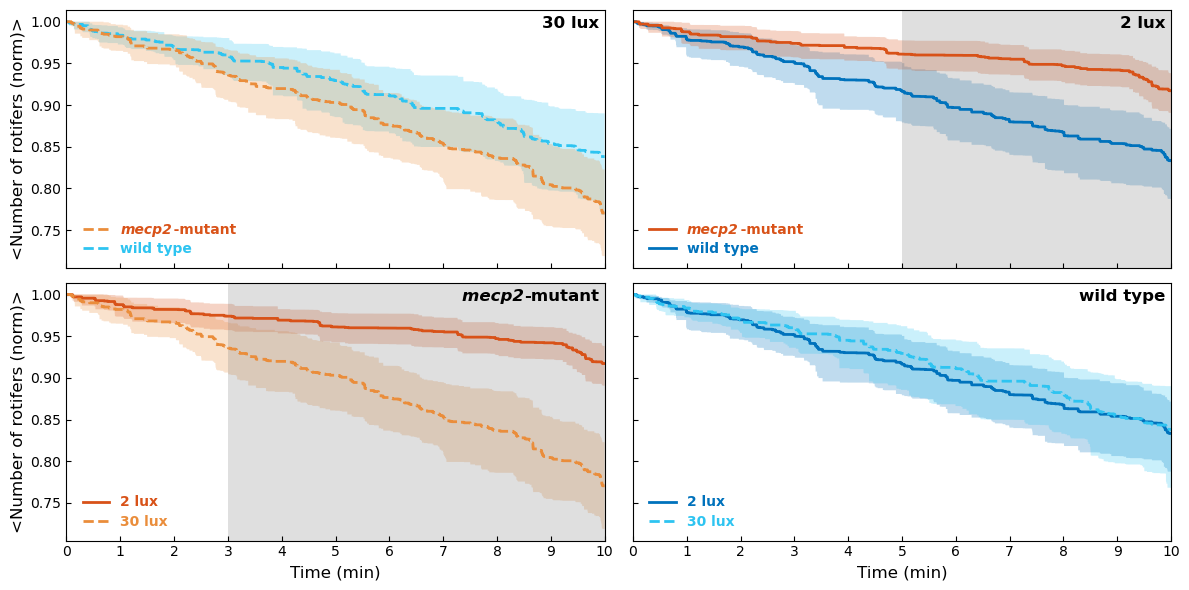

In [14]:
wt_2lux_c = '#0072bc'
wt_30lux_c = '#2ec4f1'
mecp2_2lux_c = '#d85218'
mecp2_30lux_c = '#ea8d3b'

wt_2lux_ls = '-'
wt_30lux_ls = '--'
mecp2_2lux_ls = '-'
mecp2_30lux_ls = '--'

wt_2lux_mean = np.mean(wt_2lux_data, axis=1)
wt_30lux_mean = np.mean(wt_30lux_data, axis=1)
mecp2_2lux_mean = np.mean(mecp2_2lux_data, axis=1)
mecp2_30lux_mean = np.mean(mecp2_30lux_data, axis=1)

wt_2lux_lower = np.quantile(wt_2lux_boots, ALPHA / 2, axis=0)
wt_2lux_upper = np.quantile(wt_2lux_boots, 1 - ALPHA / 2, axis=0)

wt_30lux_lower = np.quantile(wt_30lux_boots, ALPHA / 2, axis=0)
wt_30lux_upper = np.quantile(wt_30lux_boots, 1 - ALPHA / 2, axis=0)

mecp2_2lux_lower = np.quantile(mecp2_2lux_boots, ALPHA / 2, axis=0)
mecp2_2lux_upper = np.quantile(mecp2_2lux_boots, 1 - ALPHA / 2, axis=0)

mecp2_30lux_lower = np.quantile(mecp2_30lux_boots, ALPHA / 2, axis=0)
mecp2_30lux_upper = np.quantile(mecp2_30lux_boots, 1 - ALPHA / 2, axis=0)


fig, axs = plt.subplots(
    2, 2,
    sharex=True, sharey=True,
    figsize=(12, 6)
)


# ========================
#    30lux: wt vs mecp2
# ========================

axs[0, 0].plot(time_points, wt_30lux_mean, ls=wt_30lux_ls, lw=2, color=wt_30lux_c)
axs[0, 0].fill_between(time_points, wt_30lux_lower, wt_30lux_upper,
                       facecolor=wt_30lux_c, alpha=0.25)

axs[0, 0].plot(time_points, mecp2_30lux_mean, ls=mecp2_30lux_ls, lw=2, color=mecp2_30lux_c)
axs[0, 0].fill_between(time_points, mecp2_30lux_lower, mecp2_30lux_upper,
                       facecolor=mecp2_30lux_c, alpha=0.25)

for cluster, p in zip(clusters_obs_30lux, cluster_pvals_30lux):
    if p < ALPHA:
        axs[0, 0].axvspan(
            time_points[cluster[0]],
            time_points[cluster[-1]],
            facecolor='grey',
            alpha=0.25
        )

# Title
axs[0, 0].text(
    0.99, 0.975, 
    "30 lux",
    fontsize=12,
    fontweight='bold',
    transform=axs[0, 0].transAxes,  # Use axis coordinates (0–1)
    ha='right',  # horizontal alignment
    va='top'  # vertical alignment
)

# === Legend ===
axs[0, 0].plot(
    [0.03, 0.08], [0.15, 0.15],
    ls=mecp2_30lux_ls,
    lw=2,
    transform=axs[0, 0].transAxes,  # Use axis coordinates (0–1)
    color=mecp2_30lux_c,               
)
axs[0, 0].text(
    0.1, 0.175, 
    "mecp2",
    fontweight='bold',
    fontstyle='italic',
    color='#d95319',
    transform=axs[0, 0].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)
axs[0, 0].text(
    0.1, 0.175, 
    " "*11 + "-mutant",
    fontweight='bold',
    color='#d95319',
    transform=axs[0, 0].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)

axs[0, 0].plot(
    [0.03, 0.08], [0.075, 0.075],
    ls=wt_30lux_ls,
    lw=2,
    transform=axs[0, 0].transAxes,  # Use axis coordinates (0–1)
    color=wt_30lux_c,               
)
axs[0, 0].text(
    0.1, 0.1, 
    "wild type",
    fontweight='bold',
    color=wt_30lux_c,
    transform=axs[0, 0].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)


# =======================
#    2lux: wt vs mecp2
# =======================

axs[0, 1].plot(time_points, wt_2lux_mean, ls=wt_2lux_ls, lw=2, color=wt_2lux_c)
axs[0, 1].fill_between(time_points, wt_2lux_lower, wt_2lux_upper,
                       facecolor=wt_2lux_c, alpha=0.25)

axs[0, 1].plot(time_points, mecp2_2lux_mean, ls=mecp2_2lux_ls, lw=2, color=mecp2_2lux_c)
axs[0, 1].fill_between(time_points, mecp2_2lux_lower, mecp2_2lux_upper,
                       facecolor=mecp2_2lux_c, alpha=0.25)

for cluster, p in zip(clusters_obs_2lux, cluster_pvals_2lux):
    if p < ALPHA:
        axs[0, 1].axvspan(
            time_points[cluster[0]],
            time_points[cluster[-1]],
            facecolor='grey',
            alpha=0.25
        )

axs[0, 1].set_xlim(
    time_points[0], 
    time_points[-1]
)

# Title
axs[0, 1].text(
    0.99, 0.975, 
    "2 lux",
    fontsize=12,
    fontweight='bold',
    transform=axs[0, 1].transAxes,  # Use axis coordinates (0–1)
    ha='right',  # horizontal alignment
    va='top'  # vertical alignment
)

# === Legend ===
axs[0, 1].plot(
    [0.03, 0.08], [0.15, 0.15],
    ls=mecp2_2lux_ls,
    lw=2,
    transform=axs[0, 1].transAxes,  # Use axis coordinates (0–1)
    color=mecp2_2lux_c,               
)
axs[0, 1].text(
    0.1, 0.175, 
    "mecp2",
    fontweight='bold',
    fontstyle='italic',
    color=mecp2_2lux_c,
    transform=axs[0, 1].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)
axs[0, 1].text(
    0.1, 0.175, 
    " "*11 + "-mutant",
    fontweight='bold',
    color=mecp2_2lux_c,
    transform=axs[0, 1].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)

axs[0, 1].plot(
    [0.03, 0.08], [0.075, 0.075],
    ls=wt_2lux_ls,
    lw=2,
    transform=axs[0, 1].transAxes,  # Use axis coordinates (0–1)
    color=wt_2lux_c,               
)
axs[0, 1].text(
    0.1, 0.1, 
    "wild type",
    fontweight='bold',
    color=wt_2lux_c,
    transform=axs[0, 1].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)


# ==========================
#    mecp2: 2lux vs 30lux
# ==========================

axs[1, 0].plot(time_points, mecp2_2lux_mean, ls=mecp2_2lux_ls, lw=2, color=mecp2_2lux_c)
axs[1, 0].fill_between(time_points, mecp2_2lux_lower, mecp2_2lux_upper,
                       facecolor=mecp2_2lux_c, alpha=0.25)

axs[1, 0].plot(time_points, mecp2_30lux_mean, ls=mecp2_30lux_ls, lw=2, color=mecp2_30lux_c)
axs[1, 0].fill_between(time_points, mecp2_30lux_lower, mecp2_30lux_upper,
                       facecolor=mecp2_30lux_c, alpha=0.25)

for cluster, p in zip(clusters_obs_mecp2, cluster_pvals_mecp2):
    if p < ALPHA:
        axs[1, 0].axvspan(
            time_points[cluster[0]],
            time_points[cluster[-1]],
            facecolor='grey',
            alpha=0.25
        )

# Title
axs[1, 0].text(
    0.99, 0.975, 
    "mecp2" + " "*13,
    fontsize=12,
    fontweight='bold',
    fontstyle='italic',
    transform=axs[1, 0].transAxes,  # Use axis coordinates (0–1)
    ha='right',  # horizontal alignment
    va='top'  # vertical alignment
)
axs[1, 0].text(
    0.99, 0.975, 
     "-mutant",
    fontsize=12,
    fontweight='bold',
    transform=axs[1, 0].transAxes,  # Use axis coordinates (0–1)
    ha='right',  # horizontal alignment
    va='top'  # vertical alignment
)

# === Legend ===
axs[1, 0].plot(
    [0.03, 0.08], [0.15, 0.15],
    ls=mecp2_2lux_ls,
    lw=2,
    transform=axs[1, 0].transAxes,  # Use axis coordinates (0–1)
    color=mecp2_2lux_c,               
)
axs[1, 0].text(
    0.1, 0.175, 
    "2 lux",
    fontweight='bold',
    color=mecp2_2lux_c,
    transform=axs[1, 0].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)

axs[1, 0].plot(
    [0.03, 0.08], [0.075, 0.075],
    ls=mecp2_30lux_ls,
    lw=2,
    transform=axs[1, 0].transAxes,  # Use axis coordinates (0–1)
    color=mecp2_30lux_c,               
)
axs[1, 0].text(
    0.1, 0.1, 
    "30 lux",
    fontweight='bold',
    color=mecp2_30lux_c,
    transform=axs[1, 0].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)


# =======================
#    wt: 2lux vs 30lux
# =======================

axs[1, 1].plot(time_points, wt_2lux_mean, ls=wt_2lux_ls, lw=2, color=wt_2lux_c)
axs[1, 1].fill_between(time_points, wt_2lux_lower, wt_2lux_upper,
                       facecolor=wt_2lux_c, alpha=0.25)

axs[1, 1].plot(time_points, wt_30lux_mean, ls=wt_30lux_ls, lw=2, color=wt_30lux_c)
axs[1, 1].fill_between(time_points, wt_30lux_lower, wt_30lux_upper,
                       facecolor=wt_30lux_c, alpha=0.25)

for cluster, p in zip(clusters_obs_wt, cluster_pvals_wt):
    if p < ALPHA:
        axs[1, 1].axvspan(
            time_points[cluster[0]],
            time_points[cluster[-1]],
            facecolor='grey',
            alpha=0.25
        )

# Title
axs[1, 1].text(
    0.99, 0.975, 
    "wild type",
    fontsize=12,
    fontweight='bold',
    transform=axs[1, 1].transAxes,  # Use axis coordinates (0–1)
    ha='right',  # horizontal alignment
    va='top'  # vertical alignment
)

# === Legend ===
axs[1, 1].plot(
    [0.03, 0.08], [0.15, 0.15],
    ls=wt_2lux_ls,
    lw=2,
    transform=axs[1, 1].transAxes,  # Use axis coordinates (0–1)
    color=wt_2lux_c,               
)
axs[1, 1].text(
    0.1, 0.175, 
    "2 lux",
    fontweight='bold',
    color=wt_2lux_c,
    transform=axs[1, 1].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)

axs[1, 1].plot(
    [0.03, 0.08], [0.075, 0.075],
    ls=wt_30lux_ls,
    lw=2,
    transform=axs[1, 1].transAxes,  # Use axis coordinates (0–1)
    color=wt_30lux_c,               
)
axs[1, 1].text(
    0.1, 0.1, 
    "30 lux",
    fontweight='bold',
    color=wt_30lux_c,
    transform=axs[1, 1].transAxes,  # Use axis coordinates (0–1)
    ha='left',  # horizontal alignment
    va='top'  # vertical alignment
)


# === Labels & ticks ===
axs[1, 0].set_xticks(tick_positions)
axs[1, 0].set_xticklabels(tick_labels)

axs[1, 0].set_xlabel("Time (min)", fontsize=12)
axs[1, 1].set_xlabel("Time (min)", fontsize=12)

axs[0, 0].set_ylabel("<Number of rotifers (norm)>", fontsize=12)
axs[1, 0].set_ylabel("<Number of rotifers (norm)>", fontsize=12)

for ax in axs.flatten():
    ax.tick_params(direction='in')

fig.tight_layout()


# === Save and show the figure ===
fig.savefig(
    os.path.join(OUTPUT_DIR, 'Fig4A-D.svg'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()
plt.close(fig)